In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os
from numpy import mean
from numpy import std
from numpy import dstack
from pandas import read_csv
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Dropout
from keras.layers import Input
from keras.layers import LSTM
from keras.utils import to_categorical
from keras.layers import TimeDistributed
#from keras.layers.convolutional import Conv1D
#from keras.layers.convolutional import MaxPooling1D
from keras.utils import to_categorical
import tensorflow as tf
from sklearn import metrics
from sklearn.metrics import confusion_matrix


from sklearn.model_selection import train_test_split

%matplotlib inline
plt.style.use('ggplot')



#%store -r WORKDIR

if 'WORKDIR' not in dir():
    WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git'


phone_accel_data_raw_file = WORKDIR + '/Data/Raw/phone/accel'
phone_gyro_data_raw_file = WORKDIR + '/Data/Raw/phone/gyro'
watch_accel_data_raw_file = WORKDIR + '/Data/Raw/watch/accel'
watch_gyro_data_raw_file = WORKDIR + '/Data/Raw/watch/gyro'
phone_accel_data_arff_file = WORKDIR + '/Data/Arff_files/phone/accel'
phone_gyro_data_arff_file = WORKDIR + '/Data/Arff_files/phone/gyro'
watch_accel_data_arff_file = WORKDIR + '/Data/Arff_files/watch/accel'
watch_gyro_data_arff_file = WORKDIR + '/Data/Arff_files/watch/gyro'

dataset_max_date  = '2008-06-02'
dataset_min_date = '2006-01-01'

#dataset_max_date  = '2006-12-30'
#dataset_min_date = '2006-01-01'


pd.plotting.register_matplotlib_converters()

# Leitura dos Dados 

In [2]:
df_phone_accel = pd.DataFrame()
for f in glob.glob(phone_accel_data_raw_file+"/*.txt"):    
    frame = pd.read_csv(f,sep=",",header=None)
    df_phone_accel = pd.concat([df_phone_accel,frame],axis=0)  
print('shape:', df_phone_accel.shape)
df_phone_accel.head()

shape: (4804403, 6)


,0,1,2,3,4,5
0,1600,A,252207666810782,-0.364761,8.793503,1.0550842;
1,1600,A,252207717164786,-0.879730,9.768784,1.0169983;
2,1600,A,252207767518790,2.001495,11.109070,2.619156;
3,1600,A,252207817872794,0.450623,12.651642,0.18455505;
4,1600,A,252207868226798,-2.164352,13.928436,-4.4224854;


In [3]:
df_phone_accel.columns=["subject-id","activity-label","timestamp","x-sensor","y-sensor","z-sensor"]

In [4]:
df_phone_accel = df_phone_accel.replace(';','',regex=True)

In [5]:
df_phone_accel["z-sensor"] = df_phone_accel["z-sensor"].astype(float)

In [6]:
df_phone_accel.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4804403 entries, 0 to 160778
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   subject-id      int64  
 1   activity-label  object 
 2   timestamp       int64  
 3   x-sensor        float64
 4   y-sensor        float64
 5   z-sensor        float64
dtypes: float64(3), int64(2), object(1)
memory usage: 256.6+ MB


In [7]:
df_phone_accel.head()

,subject-id,activity-label,timestamp,x-sensor,y-sensor,z-sensor
0,1600,A,252207666810782,-0.364761,8.793503,1.055084
1,1600,A,252207717164786,-0.879730,9.768784,1.016998
2,1600,A,252207767518790,2.001495,11.109070,2.619156
3,1600,A,252207817872794,0.450623,12.651642,0.184555
4,1600,A,252207868226798,-2.164352,13.928436,-4.422485


In [8]:
df_phone_accel['device']="phone"

In [9]:
df_phone_accel['sensor']="accelerometer"

In [10]:
df_phone_accel.head()

,subject-id,activity-label,timestamp,x-sensor,y-sensor,z-sensor,device,sensor
0,1600,A,252207666810782,-0.364761,8.793503,1.055084,phone,accelerometer
1,1600,A,252207717164786,-0.879730,9.768784,1.016998,phone,accelerometer
2,1600,A,252207767518790,2.001495,11.109070,2.619156,phone,accelerometer
3,1600,A,252207817872794,0.450623,12.651642,0.184555,phone,accelerometer
4,1600,A,252207868226798,-2.164352,13.928436,-4.422485,phone,accelerometer


In [11]:
df_phone_gyro = pd.DataFrame()
for f in glob.glob(phone_gyro_data_raw_file+"/*.txt"):    
    frame = pd.read_csv(f,sep=",",header=None)
    df_phone_gyro = pd.concat([df_phone_gyro,frame],axis=0)  
print('shape:', df_phone_gyro.shape)
df_phone_gyro.head()

shape: (3608635, 6)


,0,1,2,3,4,5
0,1600,A,252207918580802,-0.853210,0.297226,0.8901825;
1,1600,A,252207968934806,-0.875137,0.015472,0.16223145;
2,1600,A,252208019288809,-0.720169,0.388489,-0.28401184;
3,1600,A,252208069642813,-0.571640,1.227402,-0.2416687;
4,1600,A,252208119996817,-0.380493,1.202835,-0.21313477;


In [12]:
df_phone_gyro.columns=["subject-id","activity-label","timestamp","x-sensor","y-sensor","z-sensor"]

In [13]:
df_phone_gyro = df_phone_gyro.replace(';','',regex=True)

In [14]:
df_phone_gyro["z-sensor"] = df_phone_gyro["z-sensor"].astype(float)

In [15]:
df_phone_gyro.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3608635 entries, 0 to 80347
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   subject-id      int64  
 1   activity-label  object 
 2   timestamp       int64  
 3   x-sensor        float64
 4   y-sensor        float64
 5   z-sensor        float64
dtypes: float64(3), int64(2), object(1)
memory usage: 192.7+ MB


In [16]:
df_phone_gyro['device']="phone"
df_phone_gyro['sensor']="gyroscope"

In [17]:
df_phone_gyro.head()

,subject-id,activity-label,timestamp,x-sensor,y-sensor,z-sensor,device,sensor
0,1600,A,252207918580802,-0.853210,0.297226,0.890182,phone,gyroscope
1,1600,A,252207968934806,-0.875137,0.015472,0.162231,phone,gyroscope
2,1600,A,252208019288809,-0.720169,0.388489,-0.284012,phone,gyroscope
3,1600,A,252208069642813,-0.571640,1.227402,-0.241669,phone,gyroscope
4,1600,A,252208119996817,-0.380493,1.202835,-0.213135,phone,gyroscope


In [18]:
df_watch_accel = pd.DataFrame()
for f in glob.glob(watch_accel_data_raw_file+"/*.txt"):    
    frame = pd.read_csv(f,sep=",",header=None)
    df_watch_accel = pd.concat([df_watch_accel,frame],axis=0)  
print('shape:', df_watch_accel.shape)
df_watch_accel.head()

shape: (3777046, 6)


,0,1,2,3,4,5
0,1600,A,90426708196641,7.091625,-0.591667,8.195502;
1,1600,A,90426757696641,4.972757,-0.158317,6.6967316;
2,1600,A,90426807196641,3.253720,-0.191835,6.107758;
3,1600,A,90426856696641,2.801216,-0.155922,5.997625;
4,1600,A,90426906196641,3.770868,-1.051354,7.731027;


In [19]:
df_watch_accel.columns=["subject-id","activity-label","timestamp","x-sensor","y-sensor","z-sensor"]

In [20]:
df_watch_accel = df_watch_accel.replace(';','',regex=True)

In [21]:
df_watch_accel["z-sensor"] = df_watch_accel["z-sensor"].astype(float)

In [22]:
df_watch_accel_dup = df_watch_accel[df_watch_accel.duplicated(subset=['timestamp'])]
df_watch_accel_dup.sort_values(['timestamp'])

,subject-id,activity-label,timestamp,x-sensor,y-sensor,z-sensor
75718,1629,D,377755977526809,-1.613542,-9.575759,-0.867449
75719,1629,D,377756027026809,-1.558476,-9.707440,-0.793229
75720,1629,D,377756076526809,-1.673397,-9.618854,-0.778864
75721,1629,D,377756126026809,-1.651849,-9.570971,-0.786046
75722,1629,D,377756175526809,-1.635090,-9.523087,-0.893785
...,...,...,...,...,...,...
48307,1649,O,2724263127737751,19.668966,2.956241,9.443180
48308,1649,O,2724263177680631,19.668966,5.000889,8.102427
48309,1649,O,2724263227623511,19.668966,0.930746,11.071238
48310,1649,O,2724263277566391,19.668966,6.961740,9.244462


In [23]:
df_watch_accel.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3777046 entries, 0 to 66591
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   subject-id      int64  
 1   activity-label  object 
 2   timestamp       int64  
 3   x-sensor        float64
 4   y-sensor        float64
 5   z-sensor        float64
dtypes: float64(3), int64(2), object(1)
memory usage: 201.7+ MB


In [24]:
df_watch_accel['device']="watch"
df_watch_accel['sensor']="accelerometer"

In [25]:
df_watch_accel.head()

,subject-id,activity-label,timestamp,x-sensor,y-sensor,z-sensor,device,sensor
0,1600,A,90426708196641,7.091625,-0.591667,8.195502,watch,accelerometer
1,1600,A,90426757696641,4.972757,-0.158317,6.696732,watch,accelerometer
2,1600,A,90426807196641,3.253720,-0.191835,6.107758,watch,accelerometer
3,1600,A,90426856696641,2.801216,-0.155922,5.997625,watch,accelerometer
4,1600,A,90426906196641,3.770868,-1.051354,7.731027,watch,accelerometer


array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

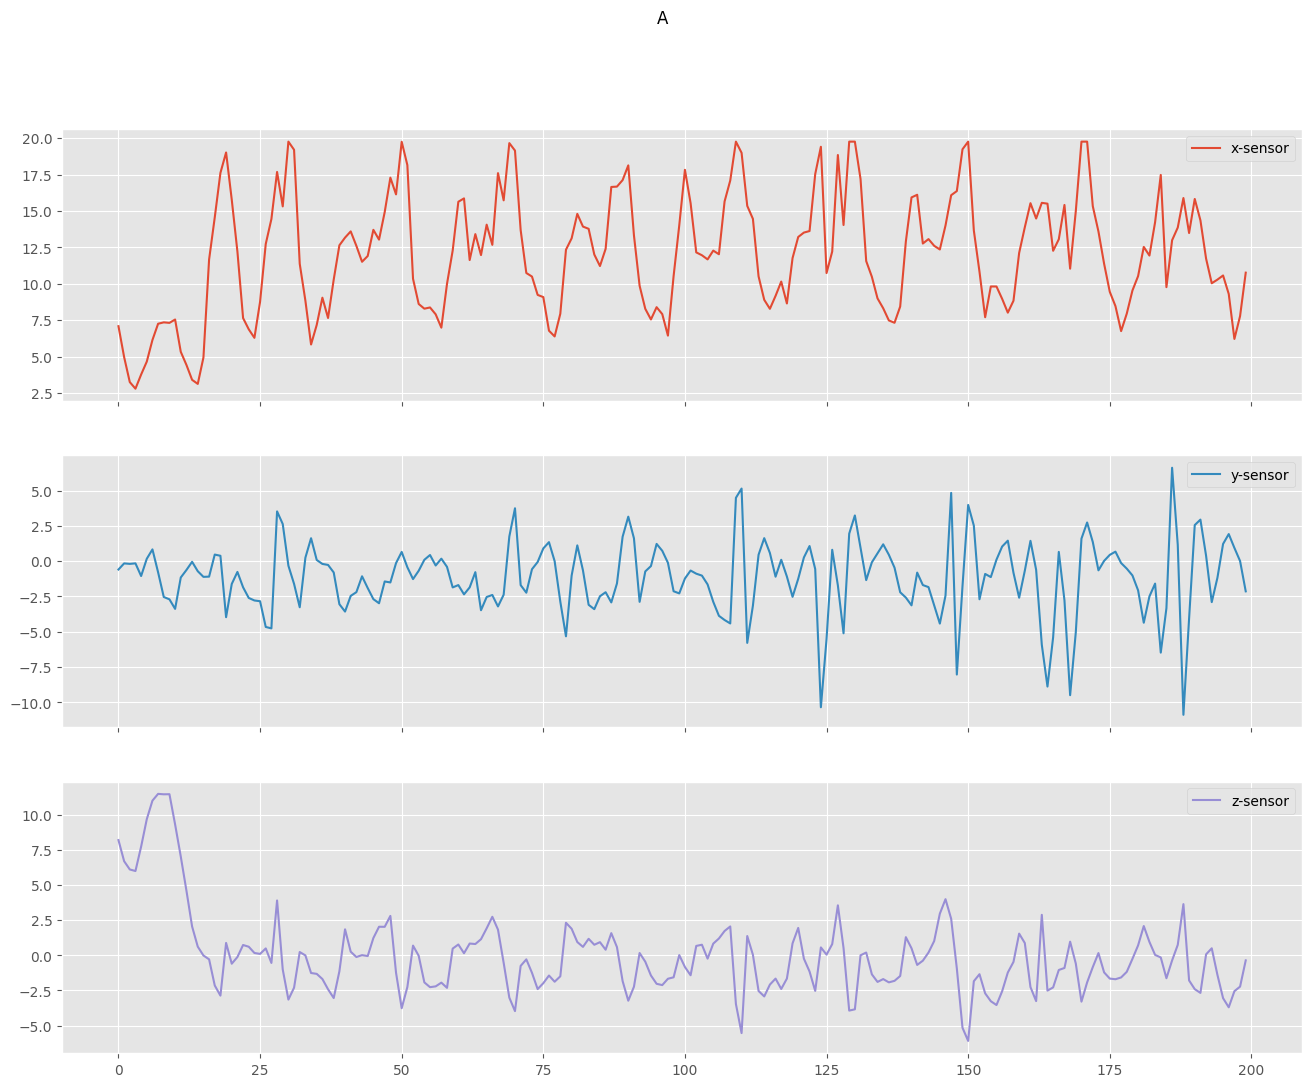

In [26]:
## x,y,z vaues for activity 'sit' 
df_watch_accel[(df_watch_accel['activity-label'] == 'A')&(df_watch_accel['subject-id']==1600)][['x-sensor', 'y-sensor', 'z-sensor']][:200].plot(title='A',subplots=True, figsize=(16, 12))

In [27]:
df_watch_accel_x_sensor.set_index('timestamp',inplace=True)

NameError: name 'df_watch_accel_x_sensor' is not defined

In [ ]:
# Color pallete for plotting
color_pal = ["#F8766D", "#D39200", "#93AA00",
             "#00BA38", "#00C19F", "#00B9E3",
             "#619CFF", "#DB72FB"]
df_watch_accel.loc[df_watch_accel.index].plot(style='.', figsize=(15,5), color=color_pal[0], title='Watch accelerometer')
plt.show()

In [ ]:
df_watch_gyro = pd.DataFrame()
for f in glob.glob(watch_gyro_data_raw_file+"/*.txt"):    
    frame = pd.read_csv(f,sep=",",header=None)
    df_watch_gyro = pd.concat([df_watch_gyro,frame],axis=0)  
print('shape:', df_watch_gyro.shape)
df_watch_gyro.head()

In [ ]:
df_watch_gyro.columns=["subject-id","activity-label","timestamp","x-sensor","y-sensor","z-sensor"]

In [ ]:
df_watch_gyro = df_watch_gyro.replace(';','',regex=True)

In [ ]:
df_watch_gyro["z-sensor"] = df_watch_gyro["z-sensor"].astype(float)

In [ ]:
df_watch_gyro.info()

In [ ]:
df_watch_gyro['device']="watch"
df_watch_gyro['sensor']="gyroscope"

In [ ]:
df_watch_gyro.head()

In [ ]:
accel_list = [df_phone_accel,df_watch_accel]
df_accel_data_phone_watch = pd.concat(accel_list)

In [ ]:
df_accel_data_phone_watch.shape

In [ ]:
df_accel_data_phone_watch.head()

In [ ]:
gyro_list = [df_phone_gyro,df_watch_gyro]
df_gyro_data_phone_watch = pd.concat(gyro_list)

In [ ]:
df_gyro_data_phone_watch.shape

In [ ]:
df_gyro_data_phone_watch.head()

In [ ]:
df_phone_accel_processed = pd.DataFrame()
for f in glob.glob(phone_accel_data_arff_file+"/*.arff"):    
    frame = pd.read_csv(f,sep=",",header=None)
    df_phone_accel_processed = pd.concat([df_phone_accel_processed,frame],axis=0)  
print('shape:', df_phone_accel_processed.shape)
df_phone_accel_processed.head()

In [ ]:
df_phone_accel_processed.columns=["ACTIVITY","X0" ,"X1" ,"X2" ,"X3" ,"X4" ,"X5" ,"X6" ,"X7" ,"X8" ,"X9" ,"Y0" ,"Y1" ,"Y2" ,"Y3" ,"Y4" ,"Y5" ,"Y6" ,"Y7" ,"Y8" ,"Y9" ,"Z0" ,"Z1" ,"Z2" ,"Z3" ,"Z4" ,"Z5" ,"Z6" ,"Z7" ,"Z8" ,"Z9" ,"XAVG" ,"YAVG" ,"ZAVG" ,"XPEAK" ,"YPEAK" ,"ZPEAK" ,"XABSOLDEV" ,"YABSOLDEV" ,"ZABSOLDEV" ,"XSTANDDEV" ,"YSTANDDEV" ,"ZSTANDDEV" ,"XVAR" ,"YVAR" ,"ZVAR" ,"XMFCC0" ,"XMFCC1" ,"XMFCC2" ,"XMFCC3" ,"XMFCC4" ,"XMFCC5" ,"XMFCC6" ,"XMFCC7" ,"XMFCC8" ,"XMFCC9" ,"XMFCC10" ,"XMFCC11" ,"XMFCC12" ,"YMFCC0" ,"YMFCC1" ,"YMFCC2" ,"YMFCC3" ,"YMFCC4" ,"YMFCC5" ,"YMFCC6" ,"YMFCC7" ,"YMFCC8" ,"YMFCC9" ,"YMFCC10" ,"YMFCC11" ,"YMFCC12" ,"ZMFCC0" ,"ZMFCC1" ,"ZMFCC2" ,"ZMFCC3" ,"ZMFCC4" ,"ZMFCC5" ,"ZMFCC6" ,"ZMFCC7" ,"ZMFCC8" ,"ZMFCC9" ,"ZMFCC10" ,"ZMFCC11" ,"ZMFCC12" ,"XYCOS" ,"XZCOS" ,"YZCOS" ,"XYCOR" ,"XZCOR" ,"YZCOR" ,"RESULTANT" ,"SUBJECT-ID"]

In [ ]:
df_phone_accel_processed.head()

In [ ]:
df_watch_accel_processed = pd.DataFrame()
for f in glob.glob(watch_accel_data_arff_file+"/*.arff"):    
    frame = pd.read_csv(f,sep=",",header=None)
    df_watch_accel_processed = pd.concat([df_watch_accel_processed,frame],axis=0)  
print('shape:', df_watch_accel_processed.shape)
df_watch_accel_processed.head()

In [ ]:
df_watch_accel_processed.columns=["ACTIVITY","X0" ,"X1" ,"X2" ,"X3" ,"X4" ,"X5" ,"X6" ,"X7" ,"X8" ,"X9" ,"Y0" ,"Y1" ,"Y2" ,"Y3" ,"Y4" ,"Y5" ,"Y6" ,"Y7" ,"Y8" ,"Y9" ,"Z0" ,"Z1" ,"Z2" ,"Z3" ,"Z4" ,"Z5" ,"Z6" ,"Z7" ,"Z8" ,"Z9" ,"XAVG" ,"YAVG" ,"ZAVG" ,"XPEAK" ,"YPEAK" ,"ZPEAK" ,"XABSOLDEV" ,"YABSOLDEV" ,"ZABSOLDEV" ,"XSTANDDEV" ,"YSTANDDEV" ,"ZSTANDDEV" ,"XVAR" ,"YVAR" ,"ZVAR" ,"XMFCC0" ,"XMFCC1" ,"XMFCC2" ,"XMFCC3" ,"XMFCC4" ,"XMFCC5" ,"XMFCC6" ,"XMFCC7" ,"XMFCC8" ,"XMFCC9" ,"XMFCC10" ,"XMFCC11" ,"XMFCC12" ,"YMFCC0" ,"YMFCC1" ,"YMFCC2" ,"YMFCC3" ,"YMFCC4" ,"YMFCC5" ,"YMFCC6" ,"YMFCC7" ,"YMFCC8" ,"YMFCC9" ,"YMFCC10" ,"YMFCC11" ,"YMFCC12" ,"ZMFCC0" ,"ZMFCC1" ,"ZMFCC2" ,"ZMFCC3" ,"ZMFCC4" ,"ZMFCC5" ,"ZMFCC6" ,"ZMFCC7" ,"ZMFCC8" ,"ZMFCC9" ,"ZMFCC10" ,"ZMFCC11" ,"ZMFCC12" ,"XYCOS" ,"XZCOS" ,"YZCOS" ,"XYCOR" ,"XZCOR" ,"YZCOR" ,"RESULTANT" ,"SUBJECT-ID"]

In [ ]:
df_watch_accel_processed.head()

In [ ]:
#accel_processed_list = [df_watch_accel_processed,df_phone_accel_processed]
#df_accel_phone_watch_processed = pd.concat(accel_processed_list)

In [ ]:
#df_accel_phone_watch_processed.shape

In [ ]:
#df_accel_phone_watch_processed.head()

In [ ]:
df_watch_accel_processed['ACTIVITY'] = df_watch_accel_processed.pop('ACTIVITY')


In [ ]:
df_watch_accel_processed.head()

In [ ]:
#df_watch_accel_processed = df_watch_accel_processed.reset_index()

In [ ]:
df_watch_accel_processed.info()

In [ ]:
df_watch_accel_processed.head()

In [ ]:
from sklearn import preprocessing
le = preprocessing.LabelEncoder()
df_watch_accel_processed['LABEL'] = le.fit_transform(df_watch_accel_processed.ACTIVITY.values)


''' def to_binary(activity):
    if activity == 'A':
        return 1 #or True
    return 0 # or False  '''

In [ ]:
#df_watch_accel_processed['LABEL'] = df_watch_accel_processed['ACTIVITY'].apply(lambda x: to_binary(x))


In [ ]:
df_watch_accel_processed = df_watch_accel_processed.sample(frac=1)

In [ ]:
df_watch_accel_processed.LABEL.value_counts()


In [ ]:
df_watch_accel_processed = df_watch_accel_processed.drop('SUBJECT-ID', axis=1)

In [ ]:
df_watch_accel_processed = df_watch_accel_processed.drop('ACTIVITY', axis=1)

In [ ]:
df_watch_accel_processed.head()

In [ ]:
df_watch_accel_processed.isnull().sum()

In [ ]:
# Everything BUT the sales column
X = df_watch_accel_processed.drop('LABEL',axis=1)
y = df_watch_accel_processed['LABEL']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [ ]:
# Reshape the data for LSTM input (samples, time steps, features)
# Assuming you want to treat each row as a sequence of features
import numpy as np
X_train_reshaped = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_test_reshaped = np.reshape(X_test, (X_test.shape[0], 1, X_test.shape[1]))

In [ ]:
print (X_train_reshaped.shape[0])

In [ ]:
print (X_train_reshaped.shape[1])

In [ ]:
print (X_train_reshaped.shape[2])

In [ ]:
print(X_train_reshaped.shape)

In [ ]:
print(y_train.shape)

In [ ]:
n_timesteps = X_train.shape[0]
n_features = X_train.shape[1]
n_outputs = y_train.shape[0]

In [ ]:
print(n_timesteps)
print(n_features)
print(n_outputs)

In [ ]:
adam = tf.keras.optimizers.Adam(learning_rate=0.01)
model = Sequential()
model.add(LSTM(units=100, activation='tanh', input_shape=(X_train_reshaped.shape[1], X_train_reshaped.shape[2])))
model.add(Dropout(0.5))
model.add(Dense(units=18,activation='softmax'))  # Output layer


# Compile the model
model.compile(optimizer=adam, loss='sparse_categorical_crossentropy',metrics=['accuracy'])

# Train the model
model.fit(X_train_reshaped, y_train, epochs=50, batch_size=128, validation_data=(X_test_reshaped, y_test))

# Evaluate the model on the test set
loss = model.evaluate(X_test_reshaped, y_test)
print(f"Test Loss: {loss}")

In [ ]:
model.summary()

In [ ]:
loss, accuracy = model.evaluate(X_test_reshaped, y_test)

In [ ]:
predict_x=model.predict(X_test_reshaped) 
classes_x=np.argmax(predict_x,axis=1)

In [ ]:
print(classes_x)

In [ ]:
matrix = metrics.confusion_matrix(y_test, classes_x)

In [ ]:
print(matrix)

In [ ]:
print(metrics.classification_report(y_test, classes_x))

In [ ]:
pjme_duplicados = pjme[pjme.duplicated(subset=['Datetime'])]

In [ ]:
pjme_duplicados.count()


# Estatistica dos dados 

In [ ]:
pjme.describe()

In [ ]:
pjme.info()

# Correção do tipo dos dados

In [ ]:
pjme['Datetime'] = pjme['Datetime'].astype('datetime64[ns]')

data_types = {
    'PJME_MW': float    
}
for cname, dtype in data_types.items():
    if dtype == int:
        pjme.loc[data[cname].astype(str) == '',cname] = '0'
    
    pjme[cname] = pjme[cname].astype(dtype)
    
pjme.describe()

In [ ]:
import random
zones = ["pacific", "mountain", "central", "eastern"]
zone = random.choice(zones)
print(zone)
    

In [ ]:
pjme.info()

In [ ]:
pjme.tail()

# Verificar Valores Nulos

In [ ]:
pjme.isnull().sum()

# Exportar Base de Dados 

In [ ]:
pjme.to_parquet(data_proc_file)